In [1]:
from ecephys_setup import get_session, get_units, get_spikes, clean_grating_spike_data

import numpy as np
import pandas as pd

import torch  
import torch.nn as nn  
import torch.optim as optim
import torch.nn.functional as F 
from torch.utils.data import TensorDataset, DataLoader

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns

from allensdk.brain_observatory.ecephys.ecephys_project_cache import EcephysProjectCache

/Users/lyn/miniforge3/envs/allensdk/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
visp_spikes = pd.read_csv("../audrey-data/visp_spikes.csv")
visal_spikes = pd.read_csv("../audrey-data/visal_spikes.csv")
drifting_table = pd.read_csv("../audrey-data/drifting_table.csv")

visp_spikes

,951869857,951869889,951869927,951869958,951870013,951870077,951870091,951870106,951870204,951870230,...,951873128,951874045,951874082,951874122,951874133,951874148,951874163,951874454,951874473,951874527
0,0.00000,2.497927,17.485487,0.000000,0.000000,0.000000,1.498756,0.499585,32.972633,24.479682,...,0.000000,0.499585,0.000000,0.999171,1.498756,0.000000,0.000000,2.997512,1.498756,0.000000
1,0.00000,3.497062,8.492866,0.000000,0.000000,0.000000,7.993286,0.000000,31.473562,43.963071,...,0.000000,6.494545,1.498741,0.499580,0.000000,0.499580,0.000000,0.999161,0.999161,10.990768
2,0.49959,0.000000,10.491397,0.000000,0.000000,0.499590,0.000000,0.000000,47.461082,19.983613,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.497952,1.498771,0.000000
3,0.00000,1.498749,20.982480,0.000000,0.000000,0.000000,3.497080,0.000000,41.465376,24.479560,...,0.499583,0.000000,0.000000,0.499583,0.499583,0.000000,0.499583,1.998331,4.995828,0.999166
4,0.00000,0.000000,7.993405,0.000000,0.000000,0.000000,12.489696,0.499588,29.975270,25.478980,...,0.000000,3.497115,0.499588,0.000000,0.000000,0.000000,0.000000,1.998351,0.999176,1.498764
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
595,0.00000,0.000000,2.497902,0.000000,0.000000,0.999161,19.483634,0.000000,31.973143,3.996643,...,0.499580,0.000000,0.999161,0.000000,1.998321,0.499580,0.000000,1.998321,0.999161,0.000000
596,0.00000,3.996703,0.999176,0.999176,0.000000,0.999176,23.480628,11.490520,37.469088,0.999176,...,0.000000,0.000000,0.999176,0.000000,1.498764,0.000000,0.999176,2.497939,4.496291,0.499588
597,0.00000,0.499580,4.995804,0.000000,1.498741,0.499580,9.492027,0.000000,20.482794,5.994964,...,0.000000,8.992446,2.497902,0.000000,0.999161,0.000000,0.000000,2.497902,2.497902,1.998321
598,0.00000,4.496201,0.999156,0.000000,0.000000,0.000000,15.486914,17.984803,30.474249,4.496201,...,0.000000,0.000000,1.498734,0.000000,1.498734,0.499578,3.996623,1.498734,3.497045,1.998311


In [3]:
visp_spikes_int = visp_spikes.multiply(2).round().astype(int)
visp_spikes_int

,951869857,951869889,951869927,951869958,951870013,951870077,951870091,951870106,951870204,951870230,...,951873128,951874045,951874082,951874122,951874133,951874148,951874163,951874454,951874473,951874527
0,0,5,35,0,0,0,3,1,66,49,...,0,1,0,2,3,0,0,6,3,0
1,0,7,17,0,0,0,16,0,63,88,...,0,13,3,1,0,1,0,2,2,22
2,1,0,21,0,0,1,0,0,95,40,...,0,0,0,0,0,0,0,5,3,0
3,0,3,42,0,0,0,7,0,83,49,...,1,0,0,1,1,0,1,4,10,2
4,0,0,16,0,0,0,25,1,60,51,...,0,7,1,0,0,0,0,4,2,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
595,0,0,5,0,0,2,39,0,64,8,...,1,0,2,0,4,1,0,4,2,0
596,0,8,2,2,0,2,47,23,75,2,...,0,0,2,0,3,0,2,5,9,1
597,0,1,10,0,3,1,19,0,41,12,...,0,18,5,0,2,0,0,5,5,4
598,0,9,2,0,0,0,31,36,61,9,...,0,0,3,0,3,1,8,3,7,4


In [4]:
orientation_labels = drifting_table[drifting_table["orientation"].notna()]["orientation"]
orientation_labels

0      225.0
1      135.0
2      225.0
3       45.0
4      135.0
       ...  
625     45.0
626    270.0
627    180.0
628     90.0
629    135.0
Name: orientation, Length: 600, dtype: float64

In [5]:
# Use GPU if available  
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [6]:
# VAE encoder
class Encoder(nn.Module):  
    def __init__(self, input_dim=784, hidden_dim=400, latent_dim=20):  
        super(Encoder, self).__init__()  
        self.fc1 = nn.Linear(input_dim, hidden_dim)  
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)  
        self.fc_logvar = nn.Linear(hidden_dim, latent_dim) 

    def forward(self, X): 
        h = torch.relu(self.fc1(X)) 
        mu = self.fc_mu(h) 
        logvar = self.fc_logvar(h) 
        return mu, logvar

# VAE decoder
class Decoder(nn.Module):  
    def __init__(self, latent_dim=20, hidden_dim=400, output_dim=784, likelihood="gaussian"):  
        super(Decoder, self).__init__()
        self.likelihood = likelihood
        self.fc1 = nn.Linear(latent_dim, hidden_dim)  
        self.fc2 = nn.Linear(hidden_dim, output_dim)
    
    def forward(self, z):
        h = torch.relu(self.fc1(z))
        out = self.fc2(h)
        if self.likelihood == "poisson":
            return F.softplus(out)      # rate λ > 0
        else:
            return out                  # Gaussian mean (real-valued)

In [7]:
# VAE class, combining encoder and decoder
class VAE(nn.Module):  
    def __init__(self, input_dim=784, hidden_dim=400, latent_dim=20, likelihood="gaussian"):  
        super(VAE, self).__init__()  
        self.encoder = Encoder(input_dim, hidden_dim, latent_dim)  
        self.decoder = Decoder(latent_dim, hidden_dim, input_dim, likelihood=likelihood)  
    
    def reparameterize(self, mu, logvar):  
        std = torch.exp(0.5 * logvar)  # Standard deviation  
        eps = torch.randn_like(std)    # Random noise  
        return mu + eps * std          # Sample from the latent distribution  
        
    def forward(self, X):  
        mu, logvar = self.encoder(X)  
        z = self.reparameterize(mu, logvar)  
        reconstructed = self.decoder(z)
        return reconstructed, mu, logvar

# VAE loss, where total loss = reconstruction loss + KL divergence
def vae_loss(recon, X, mu, logvar, likelihood):
    # Reconstruction: negative log-likelihood, averaged over batch
    if likelihood == "gaussian":
        # Gaussian NLL ∝ MSE
        recon_loss = F.mse_loss(recon, X, reduction="mean")
    elif likelihood == "poisson":
        # Poisson NLL = mean over batch of sum over units (λ - k·log λ)
        log_factorial = torch.lgamma(X + 1)
        recon_loss = (recon - X * torch.log(recon + 1e-8) + log_factorial).sum(dim=1).mean()
        recon_loss = recon_loss / (X.mean() + 1e-8)
    # KL averaged over batch
    kl_loss = -0.5 * (1 + logvar - mu.pow(2) - logvar.exp()).sum(dim=1).mean()
    return recon_loss + kl_loss, recon_loss, kl_loss

In [8]:
def run_VAE(X, likelihood, batch_size, n_epochs, learning_rate, latent_dim=2):
    # Initialize batches and model
    loader = DataLoader(TensorDataset(X), batch_size=batch_size, shuffle=True)
    
    input_dim = X.shape[1]
    model = VAE(input_dim=input_dim, latent_dim=latent_dim, likelihood=likelihood).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    
    # Track losses 
    train_losses = []
    recon_losses = []
    kl_losses = []
    
    # Training loop
    for epoch in range(n_epochs+1):
        model.train()
    
        total_train_loss = 0
        total_recon_loss = 0
        total_kl_loss = 0
        for (xb,) in loader:
            optimizer.zero_grad()
            recon, mu, logvar = model(xb)
            
            train_loss, recon_loss, kl_loss = vae_loss(recon, xb, mu, logvar, likelihood)
            total_train_loss += train_loss.item()
            total_recon_loss += recon_loss.item()
            total_kl_loss += kl_loss.item()
            
            train_loss.backward()
            optimizer.step()

        train_losses.append(total_train_loss)
        recon_losses.append(total_recon_loss)
        kl_losses.append(total_kl_loss)
        if epoch % 10 == 0:
            print(f"epoch {epoch}: loss={total_train_loss:.3f} recon={total_recon_loss:.3f} kl={total_kl_loss:.3f}")

    return model

array([  0,  45,  90, 135, 180, 225, 270, 315])

epoch 0: loss=3986.865 recon=3705.059 kl=281.807
epoch 10: loss=950.171 recon=666.523 kl=283.649
epoch 20: loss=695.751 recon=541.443 kl=154.308
epoch 30: loss=599.912 recon=478.378 kl=121.534
epoch 40: loss=598.096 recon=495.428 kl=102.669
epoch 50: loss=534.045 recon=442.272 kl=91.773
epoch 60: loss=532.061 recon=450.318 kl=81.744
epoch 70: loss=496.980 recon=417.488 kl=79.492
epoch 80: loss=503.995 recon=431.666 kl=72.328
epoch 90: loss=476.149 recon=406.111 kl=70.038
epoch 100: loss=458.148 recon=394.722 kl=63.426
epoch 110: loss=453.833 recon=390.325 kl=63.508
epoch 120: loss=449.414 recon=388.533 kl=60.881
epoch 130: loss=446.771 recon=387.256 kl=59.514
epoch 140: loss=429.078 recon=372.334 kl=56.744
epoch 150: loss=441.096 recon=385.730 kl=55.366
epoch 160: loss=428.136 recon=373.460 kl=54.676
epoch 170: loss=422.510 recon=369.792 kl=52.718
epoch 180: loss=432.896 recon=381.404 kl=51.492
epoch 190: loss=425.576 recon=374.945 kl=50.631
epoch 200: loss=424.398 recon=373.752 kl=50.

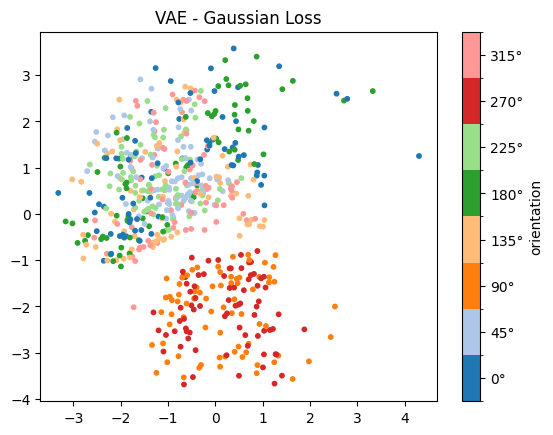

In [12]:
# Set training parameters 
n_epochs = 256
batch_size = 64
learning_rate = 1e-3 
likelihood = "gaussian"

# Initialize model, optimizer 
X = torch.tensor(visp_spikes_int.values, dtype=torch.float32).to(device)

vae_2d_model_g = run_VAE(X, likelihood, batch_size, n_epochs, learning_rate, latent_dim=2)

vae_2d_model_g.eval()
with torch.no_grad():
    mu_all, _ = vae_2d_model_g.encoder(X) # encode all available data
    Z = mu_all.cpu().numpy()
    
cmap = plt.get_cmap("tab20")   # 10 distinct colors, take first 8
orients = np.arange(0, 360, 45)
colors = [cmap(i) for i in range(len(orients))]
norm = mcolors.BoundaryNorm(boundaries=np.arange(-45 / 2, 360, 45), ncolors=8)

sc = plt.scatter(Z[:, 0], Z[:, 1], c=orientation_labels, cmap=cmap, norm=norm, s=10)
cbar = plt.colorbar(sc, ticks=orients)
cbar.ax.set_yticklabels([f"{o}°" for o in orients])
cbar.set_label("orientation")
plt.title("VAE - Gaussian Loss")
plt.show()

epoch 0: loss=2046.817 recon=1746.809 kl=300.008
epoch 10: loss=588.775 recon=443.588 kl=145.187
epoch 20: loss=461.342 recon=359.411 kl=101.931
epoch 30: loss=406.054 recon=330.586 kl=75.468
epoch 40: loss=378.945 recon=317.924 kl=61.021
epoch 50: loss=356.107 recon=303.702 kl=52.405
epoch 60: loss=345.149 recon=299.589 kl=45.560
epoch 70: loss=337.462 recon=295.277 kl=42.185
epoch 80: loss=333.193 recon=294.826 kl=38.367
epoch 90: loss=327.445 recon=290.989 kl=36.456
epoch 100: loss=327.131 recon=291.154 kl=35.977
epoch 110: loss=318.280 recon=284.449 kl=33.831
epoch 120: loss=315.413 recon=283.639 kl=31.775
epoch 130: loss=311.439 recon=280.154 kl=31.284
epoch 140: loss=310.987 recon=281.894 kl=29.094
epoch 150: loss=307.671 recon=278.373 kl=29.297
epoch 160: loss=307.075 recon=277.933 kl=29.142
epoch 170: loss=302.682 recon=275.064 kl=27.618
epoch 180: loss=302.897 recon=275.266 kl=27.631
epoch 190: loss=300.270 recon=273.866 kl=26.404
epoch 200: loss=297.300 recon=273.400 kl=23.90

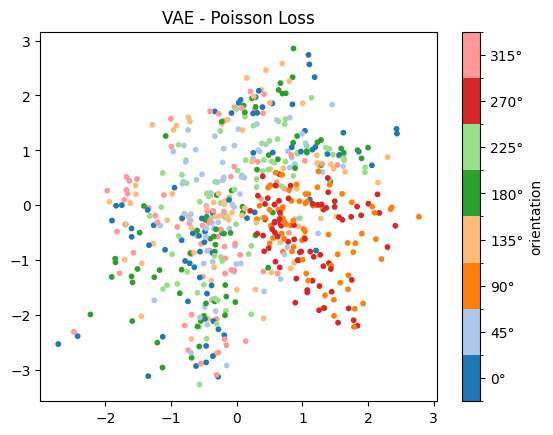

In [13]:
# Set training parameters 
n_epochs = 256
batch_size = 64
learning_rate = 1e-3 
likelihood = "poisson"

# Initialize model, optimizer 
X = torch.tensor(visp_spikes_int.values, dtype=torch.float32).to(device)

vae_2d_model_p = run_VAE(X, likelihood, batch_size, n_epochs, learning_rate, latent_dim=2)

vae_2d_model_p.eval()
with torch.no_grad():
    mu_all, _ = vae_2d_model_p.encoder(X) # encode all available data
    Z = mu_all.cpu().numpy()
    
cmap = plt.get_cmap("tab20")   # 10 distinct colors, take first 8
orients = np.arange(0, 360, 45)
colors = [cmap(i) for i in range(len(orients))]
norm = mcolors.BoundaryNorm(boundaries=np.arange(-45 / 2, 360, 45), ncolors=8)

sc = plt.scatter(Z[:, 0], Z[:, 1], c=orientation_labels, cmap=cmap, norm=norm, s=10)
cbar = plt.colorbar(sc, ticks=orients)
cbar.ax.set_yticklabels([f"{o}°" for o in orients])
cbar.set_label("orientation")
plt.title("VAE - Poisson Loss")
plt.show()

## Let's do 3D, just for fun!

epoch 0: loss=4107.684 recon=3941.112 kl=166.572
epoch 10: loss=947.787 recon=613.560 kl=334.228
epoch 20: loss=647.649 recon=447.731 kl=199.918
epoch 30: loss=552.651 recon=408.912 kl=143.740
epoch 40: loss=529.684 recon=403.566 kl=126.118
epoch 50: loss=484.202 recon=378.195 kl=106.007
epoch 60: loss=465.868 recon=369.457 kl=96.411
epoch 70: loss=450.954 recon=362.827 kl=88.127
epoch 80: loss=439.238 recon=354.483 kl=84.754
epoch 90: loss=417.754 recon=337.937 kl=79.817
epoch 100: loss=408.551 recon=332.878 kl=75.674
epoch 110: loss=411.687 recon=340.317 kl=71.370
epoch 120: loss=396.749 recon=325.286 kl=71.463
epoch 130: loss=382.797 recon=315.123 kl=67.673
epoch 140: loss=386.461 recon=316.614 kl=69.847
epoch 150: loss=376.477 recon=307.820 kl=68.658
epoch 160: loss=380.486 recon=316.175 kl=64.311
epoch 170: loss=368.253 recon=301.293 kl=66.960
epoch 180: loss=368.966 recon=300.908 kl=68.057
epoch 190: loss=361.359 recon=296.007 kl=65.352
epoch 200: loss=355.084 recon=288.943 kl=66

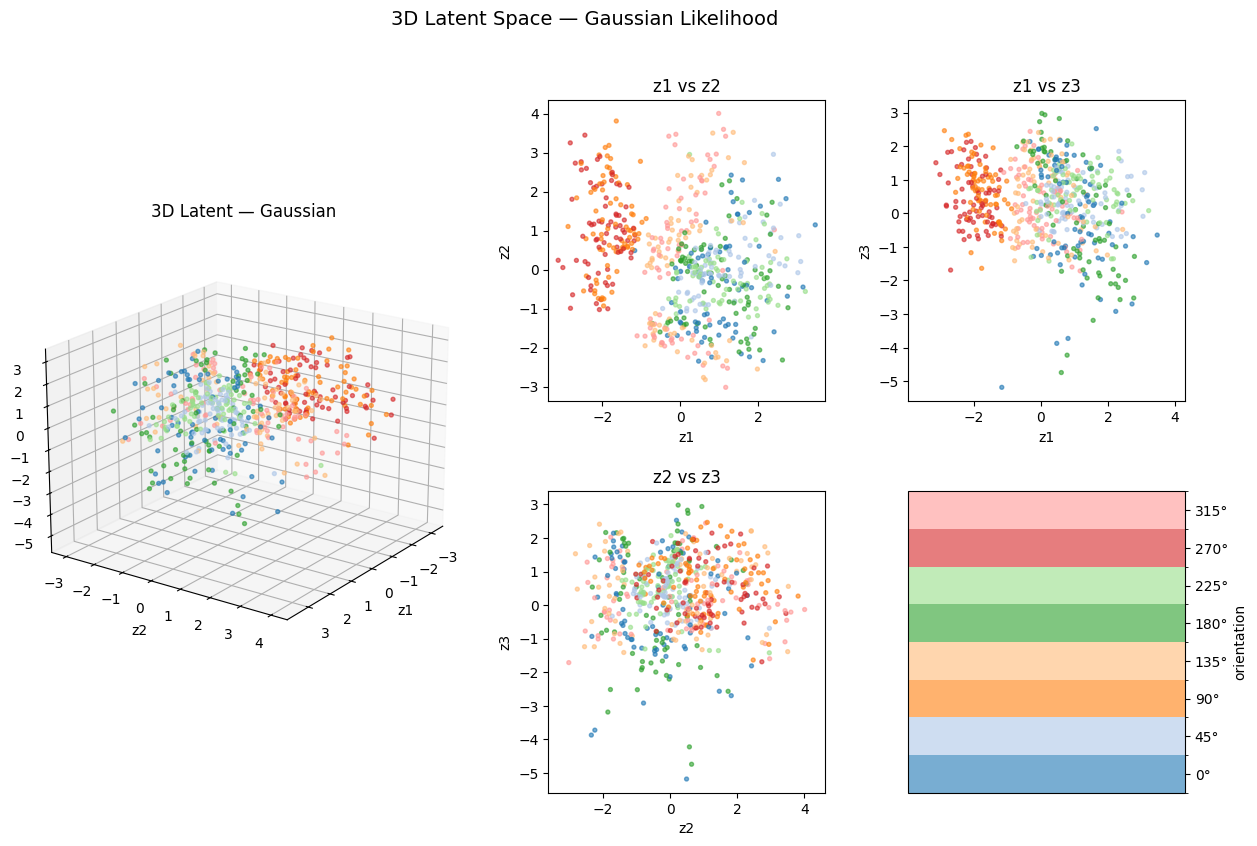

In [15]:
likelihood = "gaussian"
vae_3d_model_g = run_VAE(X, likelihood, batch_size, n_epochs, learning_rate, latent_dim=3)

vae_3d_model_g.eval()
with torch.no_grad():
    mu_all, _ = vae_3d_model_g.encoder(X)
    Z = mu_all.cpu().numpy() # (n_trials, 3)

cmap = plt.get_cmap("tab20") # 10 distinct colors, take first 8
colors = [cmap(i) for i in range(8)]
norm = mcolors.BoundaryNorm(boundaries=np.arange(-45 / 2, 360, 45), ncolors=8)

# --- figure layout: 2 rows x 3 cols; 3D spans left column (both rows) ---
fig = plt.figure(figsize=(15, 9))
gs = fig.add_gridspec(2, 3, width_ratios=[1.6, 1, 1], wspace=0.25, hspace=0.3)

# ---- (a) 3D scatter (spans left column) ----
ax3d = fig.add_subplot(gs[:, 0], projection="3d")
sc = ax3d.scatter(Z[:, 0], Z[:, 1], Z[:, 2],
                  c=orientation_labels, cmap=cmap, norm=norm,
                  s=8, alpha=0.6)
ax3d.set_xlabel("z1"); ax3d.set_ylabel("z2"); ax3d.set_zlabel("z3")
ax3d.set_title(f"3D Latent — Gaussian")
ax3d.view_init(elev=20, azim=35)

# ---- (b) three pairwise 2D projections ----
pairs = [(0, 1), (0, 2), (1, 2)]
proj_axes = [
    fig.add_subplot(gs[0, 1]),  # z1 vs z2
    fig.add_subplot(gs[0, 2]),  # z1 vs z3
    fig.add_subplot(gs[1, 1]),  # z2 vs z3
]
for ax, (i, j) in zip(proj_axes, pairs):
    ax.scatter(Z[:, i], Z[:, j], c=orientation_labels,
               cmap=cmap, norm=norm, s=8, alpha=0.6)
    ax.set_xlabel(f"z{i+1}"); ax.set_ylabel(f"z{j+1}")
    ax.set_title(f"z{i+1} vs z{j+1}")
    ax.set_aspect("equal", adjustable="datalim")

# ---- (c) shared colorbar in the bottom-right empty cell ----
cax = fig.add_subplot(gs[1, 2])
cbar = fig.colorbar(sc, cax=cax, ticks=orients)
cbar.ax.set_yticklabels([f"{o}°" for o in orients])
cbar.set_label("orientation")

plt.suptitle(f"3D Latent Space — Gaussian Likelihood", fontsize=14)
plt.show()

epoch 0: loss=4844.302 recon=2037.607 kl=2806.695
epoch 10: loss=642.184 recon=477.977 kl=164.207
epoch 20: loss=492.225 recon=377.350 kl=114.875
epoch 30: loss=435.838 recon=338.347 kl=97.491
epoch 40: loss=391.887 recon=312.474 kl=79.413
epoch 50: loss=369.147 recon=300.417 kl=68.730
epoch 60: loss=355.077 recon=289.671 kl=65.406
epoch 70: loss=342.325 recon=285.172 kl=57.153
epoch 80: loss=340.197 recon=285.467 kl=54.729
epoch 90: loss=327.344 recon=277.133 kl=50.211
epoch 100: loss=323.350 recon=273.595 kl=49.755
epoch 110: loss=316.812 recon=271.525 kl=45.287
epoch 120: loss=312.401 recon=267.050 kl=45.351
epoch 130: loss=311.096 recon=267.003 kl=44.093
epoch 140: loss=304.941 recon=262.043 kl=42.898
epoch 150: loss=301.583 recon=258.666 kl=42.917
epoch 160: loss=300.837 recon=257.750 kl=43.087
epoch 170: loss=297.977 recon=257.635 kl=40.342
epoch 180: loss=294.924 recon=253.796 kl=41.128
epoch 190: loss=292.834 recon=251.960 kl=40.874
epoch 200: loss=296.354 recon=255.964 kl=40.3

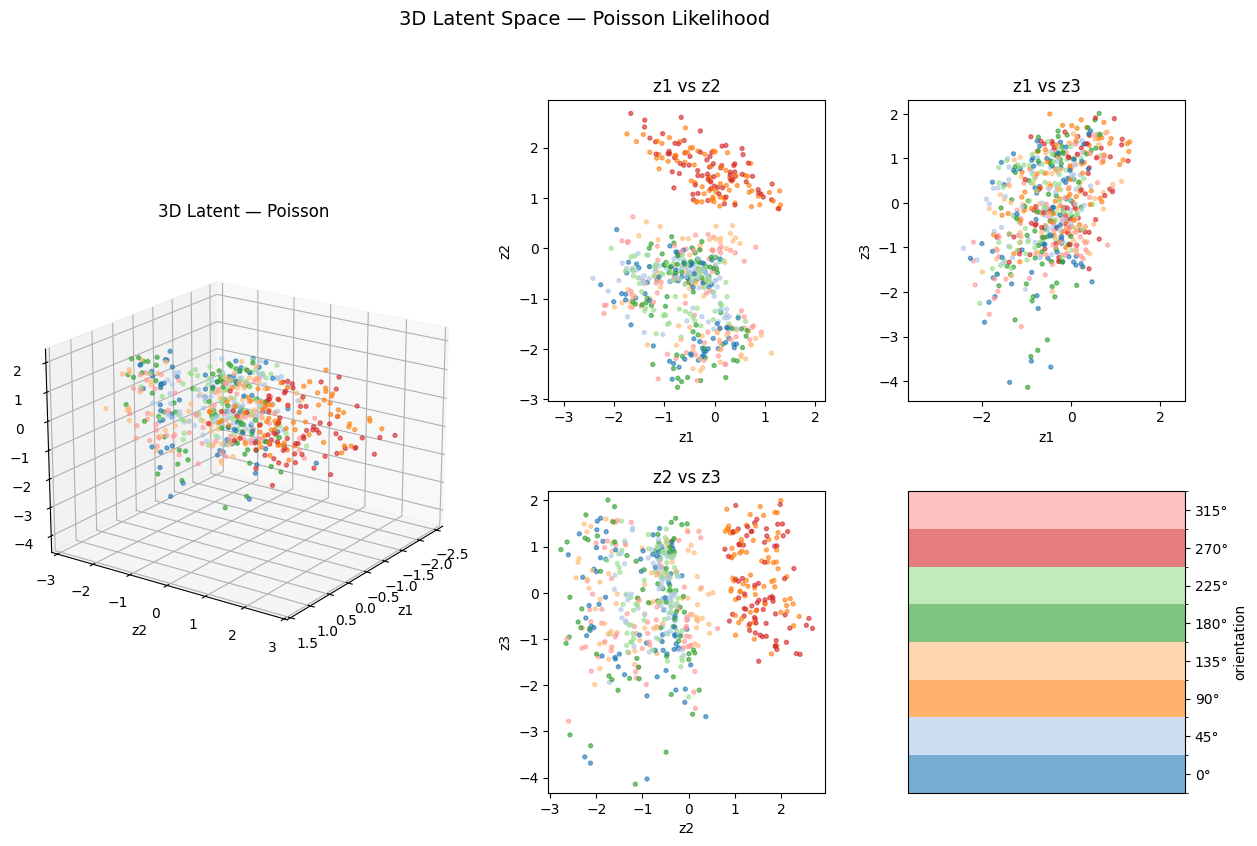

In [16]:
likelihood = "poisson"
vae_3d_model_p = run_VAE(X, likelihood, batch_size, n_epochs, learning_rate, latent_dim=3)

vae_3d_model_p.eval()
with torch.no_grad():
    mu_all, _ = vae_3d_model_p.encoder(X)
    Z = mu_all.cpu().numpy() # (n_trials, 3)

cmap = plt.get_cmap("tab20") # 10 distinct colors, take first 8
colors = [cmap(i) for i in range(8)]
norm = mcolors.BoundaryNorm(boundaries=np.arange(-45 / 2, 360, 45), ncolors=8)

# --- figure layout: 2 rows x 3 cols; 3D spans left column (both rows) ---
fig = plt.figure(figsize=(15, 9))
gs = fig.add_gridspec(2, 3, width_ratios=[1.6, 1, 1], wspace=0.25, hspace=0.3)

# ---- (a) 3D scatter (spans left column) ----
ax3d = fig.add_subplot(gs[:, 0], projection="3d")
sc = ax3d.scatter(Z[:, 0], Z[:, 1], Z[:, 2],
                  c=orientation_labels, cmap=cmap, norm=norm,
                  s=8, alpha=0.6)
ax3d.set_xlabel("z1"); ax3d.set_ylabel("z2"); ax3d.set_zlabel("z3")
ax3d.set_title(f"3D Latent — Poisson")
ax3d.view_init(elev=20, azim=35)

# ---- (b) three pairwise 2D projections ----
pairs = [(0, 1), (0, 2), (1, 2)]
proj_axes = [
    fig.add_subplot(gs[0, 1]),  # z1 vs z2
    fig.add_subplot(gs[0, 2]),  # z1 vs z3
    fig.add_subplot(gs[1, 1]),  # z2 vs z3
]
for ax, (i, j) in zip(proj_axes, pairs):
    ax.scatter(Z[:, i], Z[:, j], c=orientation_labels,
               cmap=cmap, norm=norm, s=8, alpha=0.6)
    ax.set_xlabel(f"z{i+1}"); ax.set_ylabel(f"z{j+1}")
    ax.set_title(f"z{i+1} vs z{j+1}")
    ax.set_aspect("equal", adjustable="datalim")

# ---- (c) shared colorbar in the bottom-right empty cell ----
cax = fig.add_subplot(gs[1, 2])
cbar = fig.colorbar(
    sc,
    cax=cax,
    boundaries=norm.boundaries,   # reuse the SAME edges as the scatter's BoundaryNorm
    ticks=orients,                # labels at bin centers (0, 45, ..., 315)
    spacing="proportional",       # draw swatches between boundaries, not tick marks
)
cbar.ax.set_yticklabels([f"{o}°" for o in orients])
cbar.set_label("orientation")

plt.suptitle(f"3D Latent Space — Poisson Likelihood", fontsize=14)
plt.show()